# Where to grow a building-materials distributor

A market attractiveness score for Indonesia's 514 regencies and cities (kabupaten/kota), built from BPS statistics. The use case: a distributor of cement and other building materials deciding which areas to prioritise for new branches or sales coverage.

What goes into the score:

| Factor | Indicator | Year | Direction |
|---|---|---|---|
| Market size | Population | 2025 | higher is better |
| Purchasing power | Adjusted per-capita expenditure (thousand Rp per person per year) | 2025 | higher is better |
| Momentum | Real GRDP growth | 2024 | higher is better |
| Cost to serve | Construction cost index (IKK, national average = 100) | 2025 | lower is better |
| Poverty | Share of people below the poverty line | 2025 | lower is better |

All figures are BPS releases. Sources for each variable are listed in `data/raw/bps_kabkota_2025_sources.csv`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import chart_style as cs

cs.apply()
IMAGES = ROOT / "images"
RESULTS = ROOT / "results"
SOURCE = "Source: BPS kabupaten/kota statistics (population, expenditure, IKK, poverty 2025; GRDP growth 2024)."
pd.set_option("display.width", 160)

## Load and join

The 2025 indicators and the 2024 growth figures and coordinates come from two compilations of BPS tables. Seven regions are spelled differently between them and are matched by hand.

In [2]:
indicators = pd.read_csv(ROOT / "data/raw/bps_kabkota_2025.csv")
location = pd.read_csv(ROOT / "data/raw/bps_kabkota_2024_location_growth.csv")

NAME_FIXES = {
    "Kep. Seribu": "Kepulauan Seribu",
    "Kota Makasar": "Kota Makassar",
    "Kotabaru": "Kota Baru",
    "Maluku Tenggara Barat / Kepulauan Tanimbar": "Maluku Tenggara Barat",
    "Mamuju Utara / Pasangkayu": "Mamuju Utara",
    "Pangkajene dan Kepulauan": "Pangkajene Dan Kepulauan",
    "Toba Samosir / Toba": "Toba Samosir",
}
indicators["join_name"] = indicators["kab_kota"].replace(NAME_FIXES)
regions = (
    indicators.merge(location.drop(columns="provinsi"), left_on="join_name", right_on="kab_kota",
                     how="left", suffixes=("", "_2024"), validate="one_to_one")
    .drop(columns=["join_name", "kab_kota_2024"])
    .rename(columns={"kab_kota": "region", "provinsi": "province", "pulau": "island_group", "jenis": "type",
                     "penduduk": "population", "pengeluaran_ribu_rp": "expenditure_per_capita",
                     "ipm": "hdi", "p0": "poverty_rate", "tpt": "unemployment_rate", "ikk": "construction_cost_index",
                     "economic_growth_2024": "growth"})
)
regions["region"] = regions["region"].replace({"Kota Makasar": "Kota Makassar"})

assert regions["growth"].notna().all()
print(f"{len(regions)} regions in {regions['province'].nunique()} provinces, "
      f"population {regions['population'].sum() / 1e6:.1f} million")
regions[["population", "expenditure_per_capita", "growth", "construction_cost_index", "poverty_rate"]].describe().round(1)

514 regions in 38 provinces, population 284.4 million


,population,expenditure_per_capita,growth,construction_cost_index,poverty_rate
count,514.0,514.0,514.0,514.0,514.0
mean,553382.8,11803.3,4.4,104.5,10.6
std,653436.8,2887.5,2.1,29.0,6.9
min,25028.0,4773.0,-6.0,76.7,1.9
25%,164926.8,9993.5,3.7,93.5,6.0
50%,305137.5,11684.0,4.4,98.5,8.7
75%,676224.8,13323.0,4.9,105.8,12.8
max,5721618.0,26387.0,23.5,361.4,42.6


## The score

Each indicator is turned into a percentile rank from 0 to 1, flipped where lower is better, and the five ranks are combined with fixed weights. Ranks rather than raw values keep a few extreme regions (Morowali's nickel boom, Papua's construction costs) from dominating.

In [3]:
WEIGHTS = {
    "population": 0.35,
    "expenditure_per_capita": 0.30,
    "growth": 0.15,
    "construction_cost_index": 0.10,
    "poverty_rate": 0.10,
}
LOWER_IS_BETTER = {"construction_cost_index", "poverty_rate"}

ranks = pd.DataFrame({
    col: regions[col].rank(pct=True, ascending=col not in LOWER_IS_BETTER) for col in WEIGHTS
})
regions["score"] = 100 * sum(ranks[col] * w for col, w in WEIGHTS.items())
regions["score_rank"] = regions["score"].rank(ascending=False, method="first").astype(int)

top = regions.sort_values("score", ascending=False)
cols = ["score_rank", "region", "province", "population", "expenditure_per_capita", "growth",
        "construction_cost_index", "poverty_rate", "score"]
top[cols].round(1).to_csv(RESULTS / "market_scores.csv", index=False)
top[cols].head(20).round(1)

,score_rank,region,province,population,expenditure_per_capita,growth,construction_cost_index,poverty_rate,score
263,1,Kota Surabaya,Jawa Timur,2931611.0,20679.0,5.4,100.0,3.6,92.1
419,2,Kota Makassar,Sulawesi Selatan,1473907.0,18878.0,5.3,94.3,4.4,90.7
34,3,Deli Serdang,Sumatera Utara,2078046.0,13697.0,5.1,90.1,3.1,89.2
241,4,Sidoarjo,Jawa Timur,2193692.0,16366.0,5.2,100.6,4.4,88.3
219,5,Kota Semarang,Jawa Tengah,1722421.0,17402.0,5.4,105.5,3.8,87.4
183,6,Kota Depok,Jawa Barat,2167961.0,17279.0,5.2,109.0,2.3,87.3
52,7,Kota Medan,Sumatera Utara,2498293.0,16489.0,4.8,93.5,7.2,86.9
155,8,Kota Jakarta Selatan,DKI Jakarta,2219225.0,26387.0,4.9,112.3,3.2,86.9
158,9,Kota Jakarta Barat,DKI Jakarta,2487199.0,22831.0,5.0,113.8,3.9,86.8
111,10,Kota Palembang,Sumatera Selatan,1729843.0,16725.0,4.9,88.7,9.0,86.7


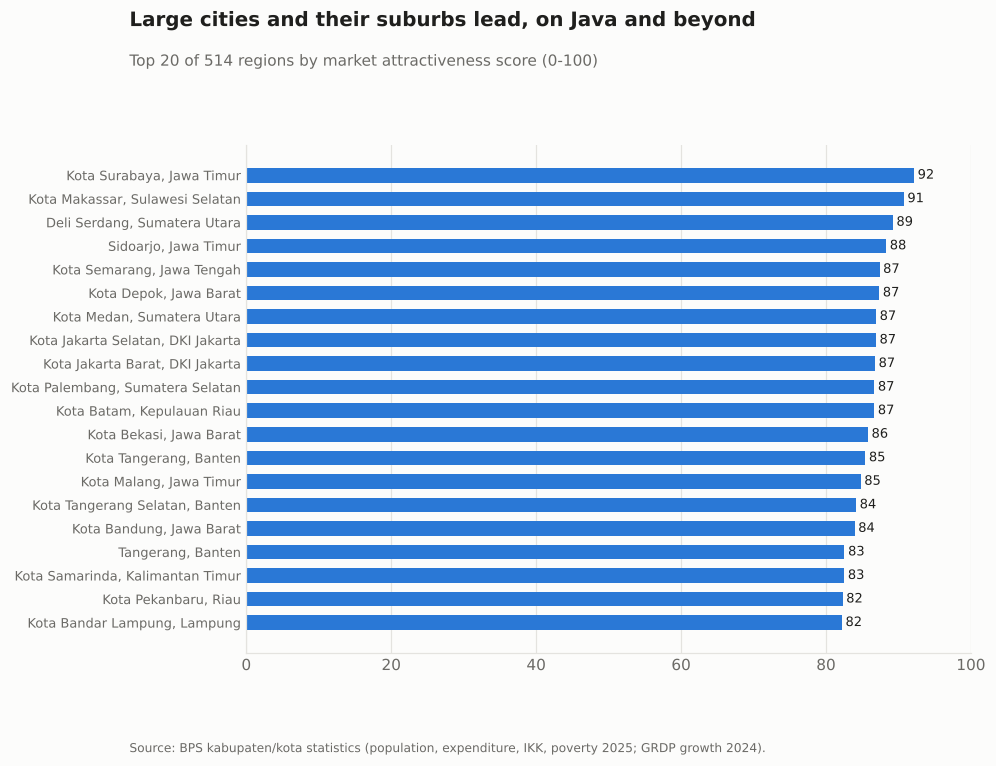

In [4]:
shown = top.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(shown["region"] + ", " + shown["province"], shown["score"], color=cs.SERIES[0], height=0.62)
for y, v in enumerate(shown["score"]):
    ax.text(v + 0.5, y, f"{v:.0f}", va="center", fontsize=8.5, color=cs.INK)
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.tick_params(axis="y", labelsize=8.5)
cs.titles(fig, "Large cities and their suburbs lead, on Java and beyond",
          "Top 20 of 514 regions by market attractiveness score (0-100)", SOURCE)
cs.save(fig, IMAGES / "01_top_regions.png")
fig

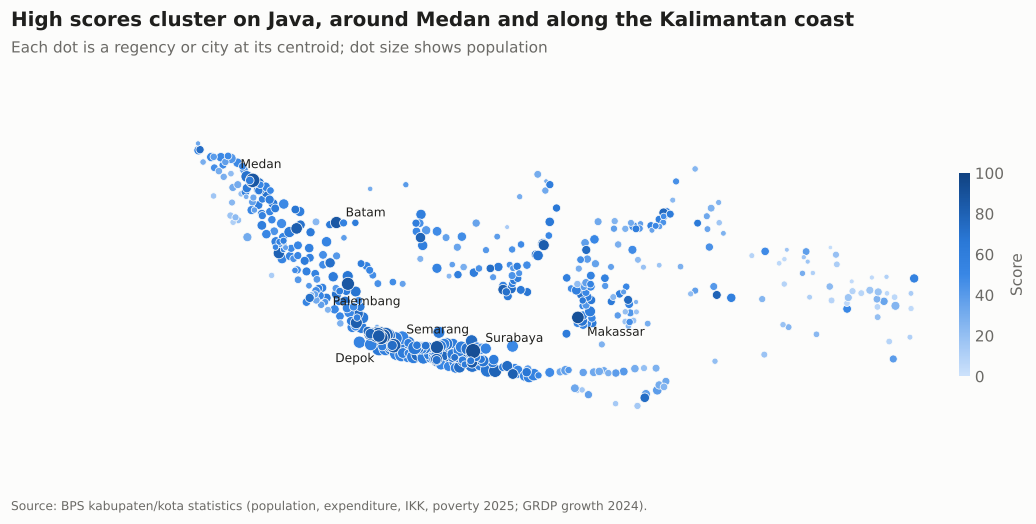

In [5]:
geo = regions.dropna(subset=["latitude", "longitude"])
fig, ax = plt.subplots(figsize=(11, 4.0))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", cs.BLUES)
pts = ax.scatter(geo["longitude"], geo["latitude"], c=geo["score"], cmap=cmap, vmin=0, vmax=100,
                 s=np.sqrt(geo["population"]) / 18, edgecolor=cs.SURFACE, linewidth=0.5)
LABELS = {"Kota Medan": (-8, 8), "Kota Palembang": (-10, -14), "Kota Depok": (-30, -16),
          "Kota Semarang": (-20, 9), "Kota Surabaya": (8, 6), "Kota Makassar": (6, -12), "Kota Batam": (6, 4)}
for _, row in geo[geo["region"].isin(LABELS)].iterrows():
    ax.annotate(row["region"].removeprefix("Kota "), (row["longitude"], row["latitude"]),
                xytext=LABELS[row["region"]], textcoords="offset points", fontsize=8, color=cs.INK)
ax.set_aspect("equal")
ax.axis("off")
bar = fig.colorbar(pts, ax=ax, shrink=0.6, pad=0.01)
bar.set_label("Score", color=cs.MUTED)
bar.outline.set_visible(False)
cs.titles(fig, "High scores cluster on Java, around Medan and along the Kalimantan coast",
          "Each dot is a regency or city at its centroid; dot size shows population", SOURCE)
cs.save(fig, IMAGES / "02_score_map.png")
fig

## How much do the weights matter?

The weights are a judgement call, so the score is recomputed 2,000 times with random weights drawn around the chosen ones (a Dirichlet distribution centred on the base weights). A region that stays in the top 50 in most runs is a safe pick; one that only makes it under the base weights is not.

In [6]:
rng = np.random.default_rng(42)
base = np.array(list(WEIGHTS.values()))
draws = rng.dirichlet(base * 25, size=2000)
rank_matrix = ranks[list(WEIGHTS)].to_numpy()

in_top50 = np.zeros(len(regions))
for w in draws:
    scores = rank_matrix @ w
    in_top50[np.argsort(-scores)[:50]] += 1
regions["top50_share"] = in_top50 / len(draws)

stable = regions[regions["top50_share"] >= 0.9]
print(f"Weights drawn per factor (5th-95th percentile):")
for name, lo, hi in zip(WEIGHTS, np.percentile(draws, 5, axis=0), np.percentile(draws, 95, axis=0)):
    print(f"  {name:<24} {lo:.2f} - {hi:.2f}")
print(f"\n{len(stable)} regions are in the top 50 in at least 90% of runs")
base_top50 = set(top.head(50)["region"])
print(f"{len(base_top50 & set(stable['region']))} of the base top 50 are among them")
regions.sort_values("top50_share", ascending=False)[["region", "province", "score_rank", "top50_share"]] \
    .round(2).to_csv(RESULTS / "weight_sensitivity.csv", index=False)

Weights drawn per factor (5th-95th percentile):
  population               0.21 - 0.51
  expenditure_per_capita   0.16 - 0.46
  growth                   0.05 - 0.28
  construction_cost_index  0.03 - 0.22
  poverty_rate             0.02 - 0.21

29 regions are in the top 50 in at least 90% of runs
29 of the base top 50 are among them


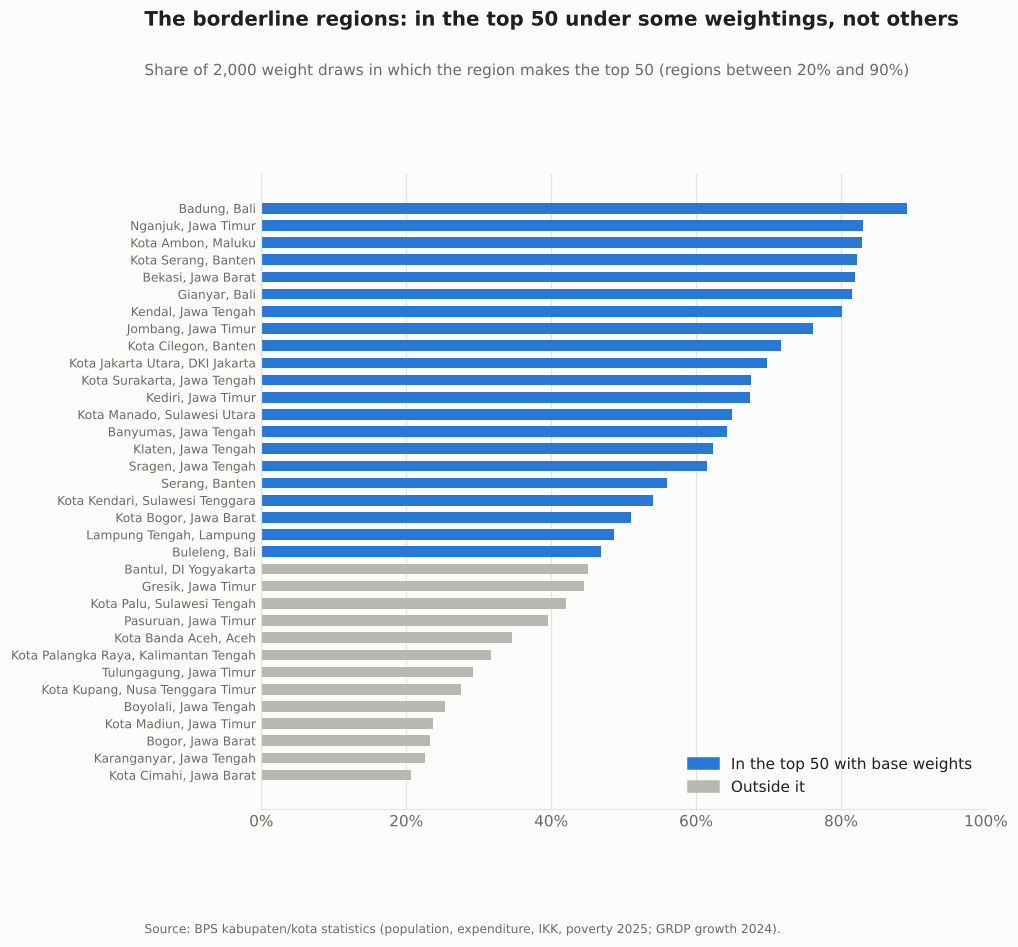

In [7]:
band = regions[(regions["top50_share"] >= 0.2) & (regions["top50_share"] < 0.9)].sort_values("top50_share")
fig, ax = plt.subplots(figsize=(8.5, 7.5))
ax.barh(band["region"] + ", " + band["province"], band["top50_share"] * 100,
        color=[cs.SERIES[0] if r <= 50 else cs.NEUTRAL for r in band["score_rank"]], height=0.62)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.tick_params(axis="y", labelsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (cs.SERIES[0], cs.NEUTRAL)]
ax.legend(handles, ["In the top 50 with base weights", "Outside it"], loc="lower right")
cs.titles(fig, "The borderline regions: in the top 50 under some weightings, not others",
          "Share of 2,000 weight draws in which the region makes the top 50 (regions between 20% and 90%)",
          SOURCE)
cs.save(fig, IMAGES / "03_sensitivity.png")
fig

## Five kinds of market

The score ranks regions on one line. Clustering on the same five indicators (log population and expenditure, growth, log IKK, poverty; all standardised) groups them by profile instead. Five clusters give groups that are easy to tell apart; each is named after its profile.

In [8]:
features = np.column_stack([
    np.log(regions["population"]),
    np.log(regions["expenditure_per_capita"]),
    regions["growth"].clip(-5, 15),
    np.log(regions["construction_cost_index"]),
    regions["poverty_rate"],
])
kmeans = KMeans(n_clusters=5, n_init=20, random_state=0).fit(StandardScaler().fit_transform(features))
regions["cluster"] = kmeans.labels_

profile = regions.groupby("cluster").agg(
    regions=("region", "size"),
    population_millions=("population", lambda s: s.sum() / 1e6),
    median_population=("population", "median"),
    median_expenditure=("expenditure_per_capita", "median"),
    median_growth=("growth", "median"),
    median_ikk=("construction_cost_index", "median"),
    median_poverty=("poverty_rate", "median"),
    median_score=("score", "median"),
)

# Name clusters from their profile rather than by hand-picked ids, so the labels
# survive a re-run that numbers the clusters differently.
names = {}
names[profile["median_ikk"].idxmax()] = "Remote, high-cost"
names[profile["median_growth"].idxmax()] = "Resource and IKN boom"
rest = profile.drop(index=list(names))
names[rest["median_population"].idxmax()] = "Large core markets"
rest = rest.drop(index=rest["median_population"].idxmax())
names[rest["median_expenditure"].idxmax()] = "Mid-size, better-off"
names[rest["median_expenditure"].idxmin()] = "Lower-income"
regions["segment"] = regions["cluster"].map(names)
profile.index = profile.index.map(names)

order = ["Large core markets", "Mid-size, better-off", "Resource and IKN boom", "Lower-income", "Remote, high-cost"]
profile = profile.loc[order]
profile.round(1).to_csv(RESULTS / "segments.csv")
profile.round(1)

,regions,population_millions,median_population,median_expenditure,median_growth,median_ikk,median_poverty,median_score
cluster,,,,,,,,
Large core markets,138,190.0,1145434.0,12568.5,4.8,99.4,8.4,70.1
"Mid-size, better-off",215,63.6,285659.0,12571.0,4.4,96.5,6.4,54.2
Resource and IKN boom,9,2.0,176083.0,11763.0,14.0,105.5,10.4,50.1
Lower-income,130,25.9,155518.0,9320.5,3.7,97.7,14.5,29.5
"Remote, high-cost",22,2.9,115918.5,6134.0,3.4,175.6,31.2,8.2


In [9]:
for seg in order:
    biggest = regions[regions["segment"] == seg].nlargest(5, "population")["region"].tolist()
    print(f"{seg:<22} {', '.join(biggest)}")

Large core markets     Bogor, Bandung, Tangerang, Bekasi, Kota Jakarta Timur
Mid-size, better-off   Indragiri Hilir, Rokan Hilir, Rokan Hulu, Bengkalis, Pacitan
Resource and IKN boom  Kutai Timur, Penajam Paser Utara, Konawe, Halmahera Selatan, Morowali
Lower-income           Bangkalan, Sampang, Lampung Utara, Aceh Utara, Bima
Remote, high-cost      Yahukimo, Jayawijaya, Tolikara, Paniai, Puncak Jaya


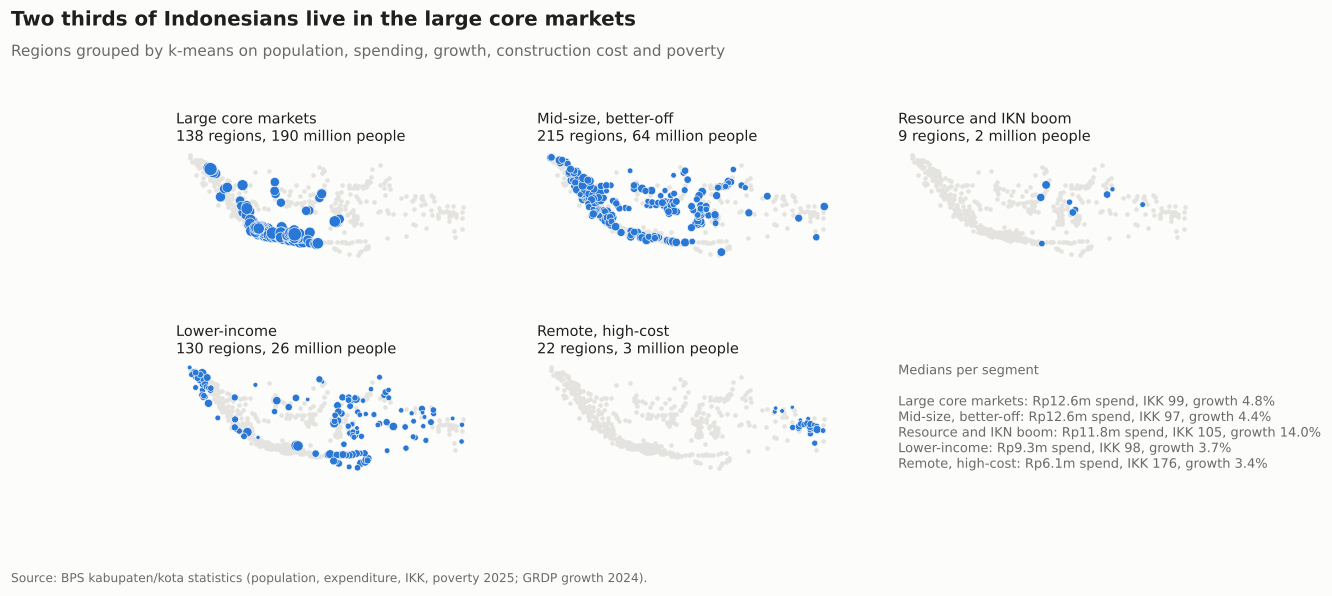

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12, 4.6))
for ax, seg in zip(axes.flat, order):
    other = geo[regions.loc[geo.index, "segment"] != seg]
    this = geo[regions.loc[geo.index, "segment"] == seg]
    ax.scatter(other["longitude"], other["latitude"], s=4, color=cs.GRID)
    ax.scatter(this["longitude"], this["latitude"], s=np.sqrt(this["population"]) / 22, color=cs.SERIES[0],
               edgecolor=cs.SURFACE, linewidth=0.4)
    row = profile.loc[seg]
    ax.set_title(f"{seg}\n{int(row['regions'])} regions, {row['population_millions']:.0f} million people",
                 loc="left", fontsize=9.5, color=cs.INK)
    ax.set_aspect("equal")
    ax.axis("off")
axes.flat[-1].axis("off")
note = ("Medians per segment\n\n" + "\n".join(
    f"{seg}: Rp{profile.loc[seg, 'median_expenditure'] / 1000:.1f}m spend, "
    f"IKK {profile.loc[seg, 'median_ikk']:.0f}, growth {profile.loc[seg, 'median_growth']:.1f}%"
    for seg in order))
axes.flat[-1].text(0, 0.5, note, fontsize=8.5, color=cs.MUTED, va="center", transform=axes.flat[-1].transAxes)
cs.titles(fig, "Two thirds of Indonesians live in the large core markets",
          "Regions grouped by k-means on population, spending, growth, construction cost and poverty", SOURCE)
cs.save(fig, IMAGES / "04_segments.png")
fig

## Province view

For coverage planning at province level: the total consumption pool (population times per-capita expenditure) and how many of the stable top-scoring regions each province holds.

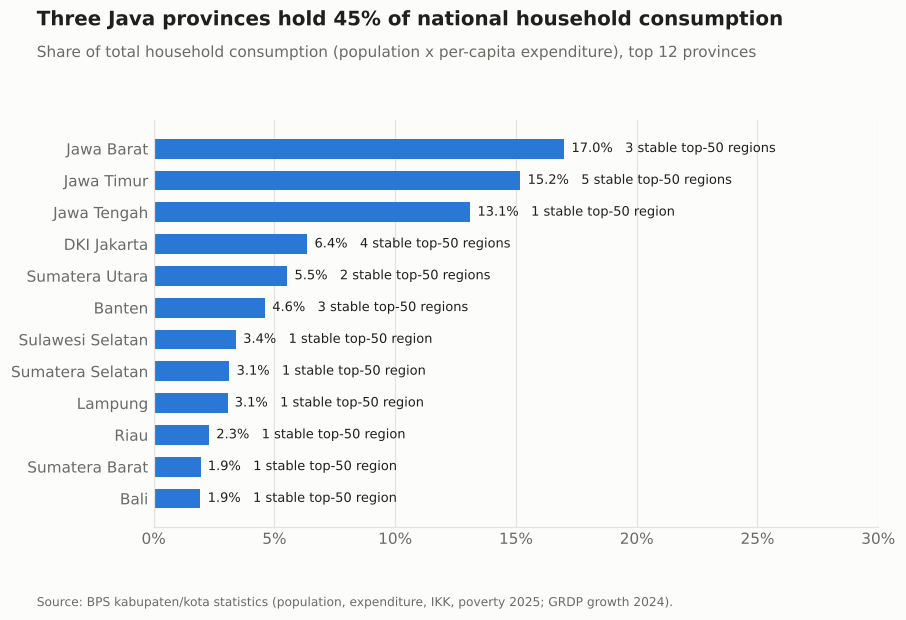

In [11]:
regions["consumption_pool"] = regions["population"] * regions["expenditure_per_capita"] * 1000
province = (
    regions.groupby("province")
    .agg(population=("population", "sum"), consumption_pool=("consumption_pool", "sum"),
         regions=("region", "size"), stable_top50=("top50_share", lambda s: (s >= 0.9).sum()))
    .sort_values("consumption_pool", ascending=False)
)
province["pool_share"] = province["consumption_pool"] / province["consumption_pool"].sum()
province.round(3).to_csv(RESULTS / "provinces.csv")

top_prov = province.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(top_prov.index, top_prov["pool_share"] * 100, color=cs.SERIES[0], height=0.62)
for y, (v, n) in enumerate(zip(top_prov["pool_share"] * 100, top_prov["stable_top50"])):
    ax.text(v + 0.3, y, f"{v:.1f}%   {n} stable top-50 region{'s' if n != 1 else ''}", va="center",
            fontsize=8.5, color=cs.INK)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 30)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
cs.titles(fig, "Three Java provinces hold 45% of national household consumption",
          "Share of total household consumption (population x per-capita expenditure), top 12 provinces",
          SOURCE)
cs.save(fig, IMAGES / "05_provinces.png")
fig

In [12]:
print(f"Jawa Barat, Jawa Timur and Jawa Tengah: {province.loc[['Jawa Barat', 'Jawa Timur', 'Jawa Tengah'], 'pool_share'].sum():.0%} of the pool")
print(f"Java as a whole: {regions.loc[regions['island_group'] == 'Jawa', 'consumption_pool'].sum() / regions['consumption_pool'].sum():.0%}")
province.head(12).round(3)

Jawa Barat, Jawa Timur and Jawa Tengah: 45% of the pool
Java as a whole: 58%


,population,consumption_pool,regions,stable_top50,pool_share
province,,,,,
Jawa Barat,50759003.0,6.264218e+14,27,3,0.170
Jawa Timur,42089271.0,5.595027e+14,38,5,0.152
Jawa Tengah,38233933.0,4.829599e+14,35,1,0.131
DKI Jakarta,10677975.0,2.344223e+14,6,4,0.064
Sumatera Utara,15785839.0,2.038815e+14,33,2,0.055
Banten,12537436.0,1.699376e+14,8,3,0.046
Sulawesi Selatan,9563127.0,1.256153e+14,24,1,0.034
Sumatera Selatan,8928515.0,1.155695e+14,17,1,0.031
Lampung,9522913.0,1.127320e+14,15,1,0.031


## Summary

- The top of the ranking is large cities and the regencies around them: Surabaya and Sidoarjo, Makassar, Medan and Deli Serdang, Semarang, Palembang, Batam and the Jakarta area. They combine big populations, above-average spending and ordinary construction costs.
- 29 of the base top 50 stay in the top 50 in at least 90% of the weight draws. The rest depend on how much weight size and growth get; those are where local competition and logistics should decide.
- Nine regions grow far faster than the rest (median 14% in 2024), driven by nickel and mining in Sulawesi and North Maluku and by the new capital (IKN) in Penajam Paser Utara. They are small today but are where construction demand is moving fastest.
- 22 regions, mostly in Papua's highlands, combine construction costs about 75% above the national average with poverty above 30%. Serving them is expensive for a distributor and they score lowest.
- At province level, Jawa Barat, Jawa Timur and Jawa Tengah hold 45% of national household consumption, and Java as a whole 58%.

Limits: the score uses household-side indicators. It does not include data a distributor would add in practice, such as current sales, competitor presence, road access or cement consumption per region. Growth is for 2024 while the other indicators are for 2025. Coordinates are region centroids.